In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import duckdb

In [2]:
PROCESSED = "../Data/Processed/"

#in-memory duckdb connection (nothing is written to disk)
con = duckdb.connect()

#views over the cleaned parquet files (column types are stored in the files)
con.execute(f"CREATE OR REPLACE VIEW orders AS SELECT * FROM read_parquet('{PROCESSED}orders_clean.parquet')");

### Order Status Analysis

In [3]:
# Calculate the total number of orders
total = con.sql(""" 
    select count(*) as total
    from orders
 """).df()

print(f"Total orders: {total.iloc[0, 0]}")

Total orders: 99441


In [4]:
#check order status of orders
order_status = con.sql(""" 
        select order_status,
                count(*) as status_number,
                count(*) * 100.0 / sum(count(*)) over () as status_percent
        from orders
        group by order_status
        order by status_number desc;
 """).df()

print("number of each order_status:")
display(order_status)

number of each order_status:


,order_status,status_number,status_percent
0,delivered,96478,97.020344
1,shipped,1107,1.113223
2,canceled,625,0.628513
3,unavailable,609,0.612423
4,invoiced,314,0.315765
5,processing,301,0.302692
6,created,5,0.005028
7,approved,2,0.002011


In [5]:
#group statuses by what they mean for the customer
status_group = {
    "delivered": "delivered",
    "canceled": "failed", "unavailable": "failed",
    "shipped": "in progress", "invoiced": "in progress", "processing": "in progress",
    "approved": "in progress", "created": "in progress",
}
order_status["group"] = order_status["order_status"].map(status_group)

group_summary = (order_status.groupby("group")[["status_number", "status_percent"]].sum()
                 .sort_values("status_number", ascending=False))
display(group_summary.round(2))

failed = group_summary.loc["failed"]
print(f"non-fulfilment rate (canceled + unavailable): {failed['status_percent']:.2f}% ({int(failed['status_number']):,} orders)")

,status_number,status_percent
group,,
delivered,96478,97.02
in progress,1729,1.74
failed,1234,1.24


non-fulfilment rate (canceled + unavailable): 1.24% (1,234 orders)


In [6]:
#status by purchase month: statuses are a snapshot taken when the data was extracted
status_by_month = con.sql("""
    select date_trunc('month', order_purchase_timestamp) as month_start,
           count(*) as orders,
           100.0 * avg(case when order_status in ('canceled', 'unavailable') then 1 else 0 end) as failed_pct,
           100.0 * avg(case when order_status in ('shipped', 'invoiced', 'processing', 'approved', 'created') then 1 else 0 end) as in_progress_pct
    from orders
    group by month_start
    order by month_start
""").df()

display(status_by_month.round({"failed_pct": 2, "in_progress_pct": 2}))

,month_start,orders,failed_pct,in_progress_pct
0,2016-09-01,4,50.00,25.00
1,2016-10-01,324,9.57,8.64
2,2016-12-01,1,0.00,0.00
3,2017-01-01,800,1.62,4.62
4,2017-02-01,1780,3.48,3.65
5,2017-03-01,2682,2.42,2.65
6,2017-04-01,2404,1.12,3.08
7,2017-05-01,3700,1.62,2.54
8,2017-06-01,3245,1.23,2.16
9,2017-07-01,4026,1.99,1.84


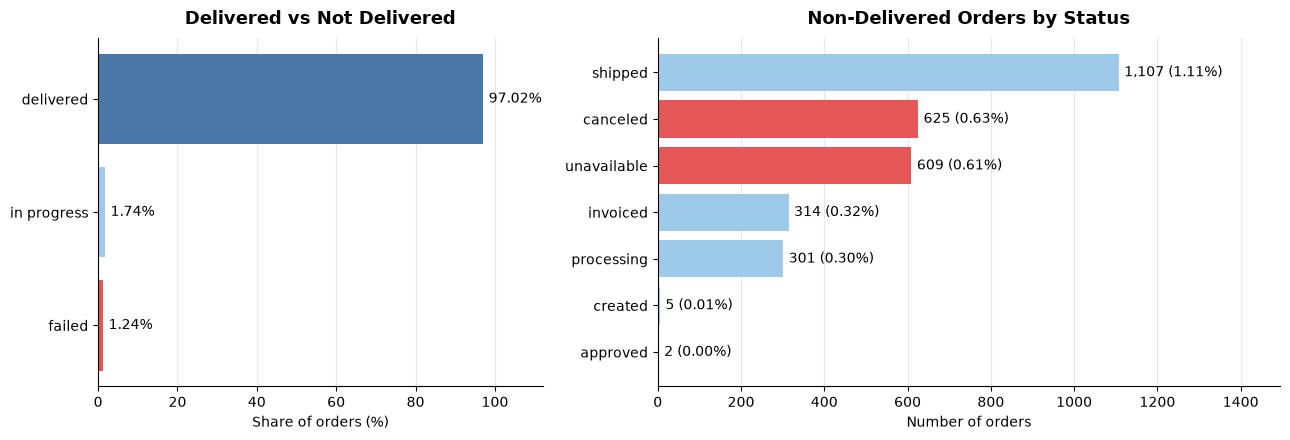

In [7]:
#visualizing chart: delivered vs not delivered, then the non-delivered statuses on their own
group_order = ["delivered", "in progress", "failed"]
group_colors = {"delivered": "#4C78A8", "in progress": "#9ECAE9", "failed": "#E45756"}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1, 1.4]})

# left: share of each group
g = group_summary.reindex(group_order)
bars = ax1.barh(g.index[::-1], g["status_percent"][::-1],
                color=[group_colors[x] for x in g.index[::-1]])
ax1.bar_label(bars, fmt="%.2f%%", padding=4, fontsize=10)
ax1.set_title("Delivered vs Not Delivered", fontsize=13, fontweight="bold", pad=10)
ax1.set_xlabel("Share of orders (%)")
ax1.set_xlim(0, 112)

# right: non-delivered statuses only
nd = (order_status[order_status["group"] != "delivered"]
      .sort_values("status_number", ascending=True))
bars = ax2.barh(nd["order_status"], nd["status_number"],
                color=[group_colors[x] for x in nd["group"]])
ax2.bar_label(bars, labels=[f"{n:,} ({p:.2f}%)" for n, p in zip(nd["status_number"], nd["status_percent"])],
              padding=4, fontsize=10)
ax2.set_title("Non-Delivered Orders by Status", fontsize=13, fontweight="bold", pad=10)
ax2.set_xlabel("Number of orders")
ax2.set_xlim(0, nd["status_number"].max() * 1.35)

for ax in (ax1, ax2):
    ax.grid(axis="x", alpha=0.3)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

#### Order Status Analysis – Conclusion

The Olist dataset contains **99,441 orders**, of which **97.02% (96,478)** were delivered.

**Non-delivered orders (2.98%) fall into two very different groups:**
- **Failed (1.24%, 1,234 orders):** `canceled` (625) and `unavailable` (609). "Unavailable" orders also failed (the product could not be supplied), so the non-fulfilment rate is **1.24%**, about twice the 0.63% cancellation rate alone.
- **In progress (1.74%, 1,729 orders):** `shipped`, `invoiced`, `processing`, `approved`, and `created`. Statuses are a snapshot taken when the data was extracted, so most of these orders were simply not finished yet.

**By purchase month:** within the valid window (Jan 2017 to Aug 2018), the failed share stays between about 0.3% and 3.5% per month, and the in-progress share between about 0.8% and 4.6%. Outside it, the shares are extreme (Sep 2018: 93.75% failed; Oct 2018: 100%), which is one more sign that those months are artefacts of the data cutoff.

**Business Insight:**

Olist delivers almost all of its orders. The real failure rate is 1.24%, and about half of it comes from unavailable products rather than customer cancellations, so stock availability is worth investigating alongside cancellations.

### Monthly Order Analysis & Yearly Comparison

In [8]:
monthly_order = con.sql(""" 
    select order_month,
            order_year,
            count(*) as orders_count
    from orders
    group by order_year, order_month
    order by order_year ,order_month
""").df()

# Real date column, so months sort and plot chronologically
monthly_order["month_start"] = pd.to_datetime(
    dict(year=monthly_order["order_year"], month=monthly_order["order_month"], day=1)
)

#set month abbreviation
monthly_order['month_abbr'] = monthly_order['month_start'].dt.strftime('%b')


print("number of orders for each month:")
display(monthly_order[["month_start","month_abbr","orders_count"]])


number of orders for each month:


,month_start,month_abbr,orders_count
0,2016-09-01,Sep,4
1,2016-10-01,Oct,324
2,2016-12-01,Dec,1
3,2017-01-01,Jan,800
4,2017-02-01,Feb,1780
5,2017-03-01,Mar,2682
6,2017-04-01,Apr,2404
7,2017-05-01,May,3700
8,2017-06-01,Jun,3245
9,2017-07-01,Jul,4026


In [9]:
# Valid analysis window 
START = pd.Timestamp("2017-01-01")
END   = pd.Timestamp("2018-08-01")   # last valid month (month-start date)

# Fill missing months (e.g. Nov 2016 has no row) with 0 so the line doesn't skip them
full_range = pd.date_range(monthly_order["month_start"].min(),
                           monthly_order["month_start"].max(), freq="MS")
timeline = (monthly_order.set_index("month_start")["orders_count"]
            .reindex(full_range, fill_value=0))

In [10]:
#valid range information
valid = timeline[START:END]

max_date, max_val = valid.idxmax(), valid.max()
min_date, min_val = valid.idxmin(), valid.min()

print("number of orders in valid range date:")
display(valid.to_frame())
print(f"month with the most orders  : {max_date.strftime('%B %Y')} with {max_val:,} orders")
print(f"month with the fewest orders: {min_date.strftime('%B %Y')} with {min_val:,} orders")


number of orders in valid range date:


,orders_count
2017-01-01,800
2017-02-01,1780
2017-03-01,2682
2017-04-01,2404
2017-05-01,3700
2017-06-01,3245
2017-07-01,4026
2017-08-01,4331
2017-09-01,4285
2017-10-01,4631


month with the most orders  : November 2017 with 7,544 orders
month with the fewest orders: January 2017 with 800 orders


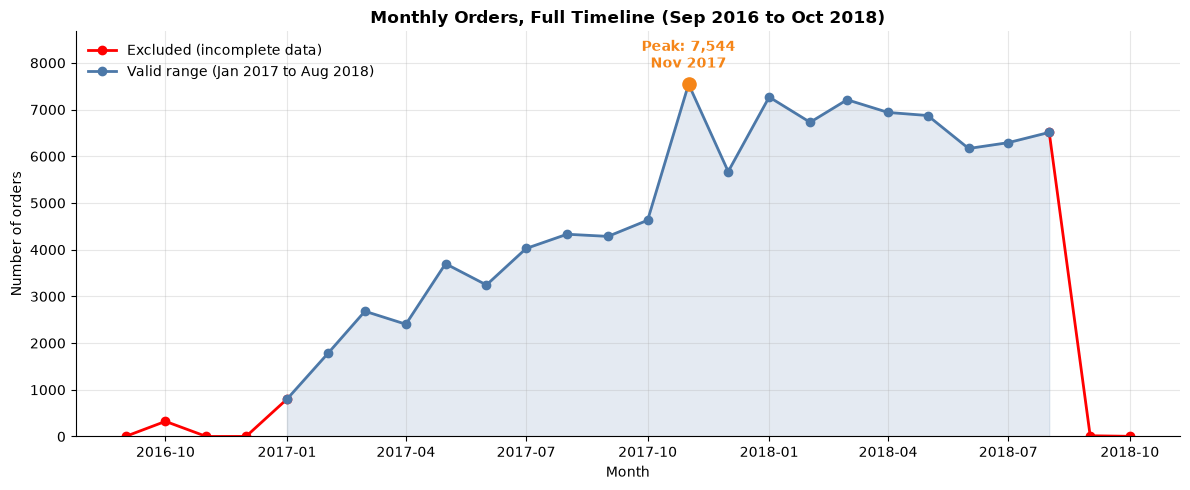

In [11]:
#Monthly Orders, Full Timeline chart
fig, ax = plt.subplots(figsize=(12, 5))

# Split the timeline into three parts
# (slicing is inclusive on both ends, so the boundary month is shared and the lines connect)
left_excluded  = timeline[:START]    # Sep 2016 to Jan 2017
valid          = timeline[START:END] # Jan 2017 to Aug 2018
right_excluded = timeline[END:]      # Aug 2018 to Oct 2018

# Excluded parts in red
ax.plot(left_excluded.index, left_excluded.values,
        marker="o", color="red", linewidth=2, label="Excluded (incomplete data)")
ax.plot(right_excluded.index, right_excluded.values,
        marker="o", color="red", linewidth=2)

# Valid window in blue, drawn on top so the shared boundary points stay blue
ax.plot(valid.index, valid.values,
        marker="o", color="#4C78A8", linewidth=2, zorder=3,
        label="Valid range (Jan 2017 to Aug 2018)")

# Light fill under the valid window only
ax.fill_between(valid.index, valid.values, color="#4C78A8", alpha=0.15)

# Peak inside the valid window
peak_date  = valid.idxmax()
peak_value = valid.max()
ax.scatter(peak_date, peak_value, color="#F58518", s=90, zorder=5)
ax.annotate(f"Peak: {peak_value:,}\n{peak_date.strftime('%b %Y')}",
            xy=(peak_date, peak_value),
            xytext=(0, 12), textcoords="offset points",
            ha="center", color="#F58518", fontweight="bold")

ax.set_ylim(0, timeline.max() * 1.15)
ax.set_title("Monthly Orders, Full Timeline (Sep 2016 to Oct 2018)", fontweight="bold")
ax.set_xlabel("Month")
ax.set_ylabel("Number of orders")
ax.grid(axis="y", alpha=0.3)
ax.grid(axis="x", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

In [12]:
#why the excluded months are excluded: statuses outside the valid window
excluded = con.sql("""
    select strftime(order_purchase_timestamp, '%Y-%m') as month, order_status, count(*) as orders
    from orders
    where order_purchase_timestamp < '2017-01-01' or order_purchase_timestamp >= '2018-09-01'
    group by all
    order by all
""").df()
display(excluded.pivot(index="month", columns="order_status", values="orders").fillna(0).astype(int))

missing_months = timeline[timeline == 0].index.strftime("%Y-%m").tolist()
print("months with no orders at all:", missing_months)

order_status,canceled,delivered,invoiced,processing,shipped,unavailable
month,,,,,,
2016-09,2,1,0,0,1,0
2016-10,24,265,18,2,8,7
2016-12,0,1,0,0,0,0
2018-09,15,0,0,0,1,0
2018-10,4,0,0,0,0,0


months with no orders at all: ['2016-11']


#### Black Friday check (daily orders)

top 5 days:


,orders
day,
2017-11-24,1176
2017-11-25,499
2017-11-27,403
2017-11-26,391
2017-11-28,380


typical day in Oct to mid-Nov 2017 (median): 158 orders
Black Friday 2017-11-24: 1,176 orders (7.5x a typical day)
November without Black Friday weekend (24-27): 5,075 of 7,544 orders


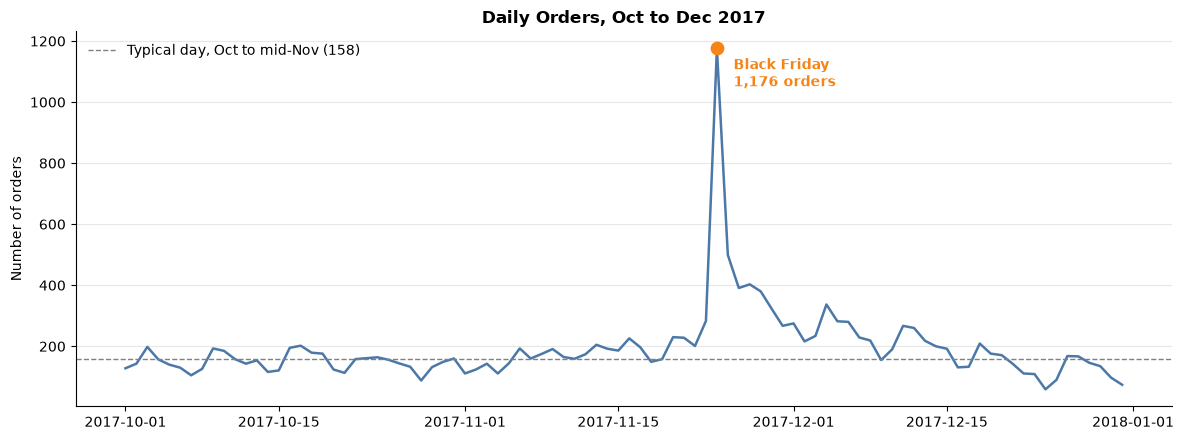

In [13]:
#daily orders around November 2017
daily = con.sql("""
    select cast(order_purchase_timestamp as date) as day, count(*) as orders
    from orders
    where order_purchase_timestamp >= '2017-10-01' and order_purchase_timestamp < '2018-01-01'
    group by day
    order by day
""").df()
daily["day"] = pd.to_datetime(daily["day"])
daily = daily.set_index("day")["orders"]

black_friday = pd.Timestamp("2017-11-24")
typical = daily["2017-10-01":"2017-11-17"].median()

print("top 5 days:")
display(daily.nlargest(5).to_frame())
print(f"typical day in Oct to mid-Nov 2017 (median): {typical:.0f} orders")
print(f"Black Friday 2017-11-24: {daily[black_friday]:,} orders ({daily[black_friday] / typical:.1f}x a typical day)")

nov = daily["2017-11-01":"2017-11-30"]
print(f"November without Black Friday weekend (24-27): {nov.drop(pd.date_range('2017-11-24', '2017-11-27')).sum():,} "
      f"of {nov.sum():,} orders")

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(daily.index, daily.values, color="#4C78A8", linewidth=1.8)
ax.axhline(typical, color="gray", linestyle="--", linewidth=1, label=f"Typical day, Oct to mid-Nov ({typical:.0f})")
ax.scatter(black_friday, daily[black_friday], color="#F58518", s=80, zorder=5)
ax.annotate(f"Black Friday\n{daily[black_friday]:,} orders",
            xy=(black_friday, daily[black_friday]), xytext=(12, -6), textcoords="offset points",
            color="#F58518", fontweight="bold", va="top")
ax.set_title("Daily Orders, Oct to Dec 2017", fontweight="bold")
ax.set_ylabel("Number of orders")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

#### Monthly Orders: Conclusion

**What is counted:** all orders **placed**, whatever their status (canceled and unavailable orders included). This measures demand. Later analyses of revenue or delivery should use delivered orders only.

**Valid window:** Jan 2017 to Aug 2018. The excluded months are artefacts of data collection, not real activity:
- Sep to Dec 2016: 329 orders in total. Nov 2016 has **no orders at all** and Dec 2016 has 1, so collection had a gap.
- Sep to Oct 2018: 20 orders in total, **all canceled except 1 shipped**. These are leftovers of the data cutoff.

**Highest and lowest months (valid window)**
- Highest: **November 2017** with **7,544** orders.
- Lowest: **January 2017** with **800** orders. This is the start of the ramp-up, not a real low. After the growth phase, the lowest month is June 2018 (6,167).

**Trend**
- **Growth (Jan to Oct 2017):** orders rose from 800 to 4,631 (about 5.8x), with small dips in April and June that recovered the next month.
- **Black Friday (Nov 2017):** orders jumped 63% in one month. The daily data confirms the cause: **Black Friday (2017-11-24) had 1,176 orders, 7.5x a typical day** (158), and the Black Friday weekend (24 to 27 Nov) alone brought 2,469 orders, about a third of the month.
- **Step-up, not only a spike:** even without the Black Friday weekend, November had 5,075 orders, already above October (4,631). From January 2018, orders stayed between about 6,200 and 7,300 per month, so volume moved to a higher baseline.
- **Plateau (Dec 2017 to Aug 2018):** per day, orders peaked in Feb 2018 (240 per day; the monthly total looks lower only because February is short) and then drifted down to about 203–210 per day in Jul and Aug 2018.

**Key takeaway:** The volume of orders grew strongly in 2017. Black Friday 2017 caused a large one-time spike, and volume also settled at a higher baseline afterwards. Growth then stalled, with a slow decline through mid-2018.

**Limitations**
- Only one full year (2017) is available, so **recurring** seasonality cannot be confirmed. The Black Friday spike itself is confirmed by the daily data, but whether it repeats every year is not.
- Order count measures volume only, not revenue, profit, or customer satisfaction.
- Month lengths differ, so growth comparisons use orders per day (`orders_per_day` in the MoM table) next to the raw monthly totals.

In [14]:
# Valid analysis window 
START = pd.Timestamp("2017-01-01")
END   = pd.Timestamp("2018-08-01")   # last valid month (month-start date)

#monthly order per year in valid range
valid_range = monthly_order.loc[monthly_order["month_start"].between(START,END)]

#month names for tables and charts (Jan to Dec)
month_labels = valid_range.loc[valid_range["order_year"] == 2017, "month_abbr"].tolist()
display(valid_range[["month_start" , "order_year" ,"order_month","month_abbr" ,"orders_count"]])

,month_start,order_year,order_month,month_abbr,orders_count
3,2017-01-01,2017,1,Jan,800
4,2017-02-01,2017,2,Feb,1780
5,2017-03-01,2017,3,Mar,2682
6,2017-04-01,2017,4,Apr,2404
7,2017-05-01,2017,5,May,3700
8,2017-06-01,2017,6,Jun,3245
9,2017-07-01,2017,7,Jul,4026
10,2017-08-01,2017,8,Aug,4331
11,2017-09-01,2017,9,Sep,4285
12,2017-10-01,2017,10,Oct,4631


In [15]:
year_2017 = valid_range.loc[valid_range["order_year"] == 2017]

print("--- orders information in 2017 ---")
print("month with the most orders in 2017:" \
    f" {year_2017.loc[year_2017["orders_count"].idxmax(),"month_abbr"]}" \
     f" with {year_2017["orders_count"].max()} orders")
print("month with the least orders in 2017:" \
    f" {year_2017.loc[year_2017["orders_count"].idxmin(),"month_abbr"]}" \
     f" with {year_2017["orders_count"].min()} orders")



year_2018 = valid_range.loc[valid_range["order_year"] == 2018]

print("\n--- orders information in 2018 ---")
print("month with the most orders in 2018:" \
    f" {year_2018.loc[year_2018["orders_count"].idxmax(),"month_abbr"]}" \
     f" with {year_2018["orders_count"].max()} orders")
print("month with the least orders in 2018:" \
    f" {year_2018.loc[year_2018["orders_count"].idxmin(),"month_abbr"]}" \
     f" with {year_2018["orders_count"].min()} orders")


--- orders information in 2017 ---
month with the most orders in 2017: Nov with 7544 orders
month with the least orders in 2017: Jan with 800 orders

--- orders information in 2018 ---
month with the most orders in 2018: Jan with 7269 orders
month with the least orders in 2018: Jun with 6167 orders


In [16]:
#find top 5 month
top_5 = valid_range.sort_values(by="orders_count", ascending=False, ignore_index=True)

display(top_5.loc[:4,["order_year","month_abbr","orders_count"]]) 

,order_year,month_abbr,orders_count
0,2017,Nov,7544
1,2018,Jan,7269
2,2018,Mar,7211
3,2018,Apr,6939
4,2018,May,6873


In [17]:
valid = timeline[START:END]

# Month-over-month % change (first month is NaN, which is correct)
mom = valid.pct_change().mul(100).round(1)
#orders per day removes the effect of month length (e.g. February has 28 days)
per_day = valid / valid.index.days_in_month
mom_table = pd.DataFrame({
    "orders": valid,
    "mom_%": mom,
    "orders_per_day": per_day.round(1),
    "mom_per_day_%": per_day.pct_change().mul(100).round(1),
})

print("mom table:")
display(mom_table)


# YoY, same months only (Jan to Aug)
y17 = timeline["2017-01-01":"2017-08-01"]
y18 = timeline["2018-01-01":"2018-08-01"]
yoy = pd.DataFrame({"2017": y17.values, "2018": y18.values},
                   index=month_labels[:8])
yoy["yoy_%"] = ((yoy["2018"] / yoy["2017"] - 1) * 100).round(1)

print("yoy table :")
display(yoy)


print("Fair yearly comparison: same months only (Jan to Aug)")
jan_aug = valid[valid.index.month <= 8]
display(jan_aug.groupby(jan_aug.index.year).agg(["sum", "mean"]).round(0))

mom table:


,orders,mom_%,orders_per_day,mom_per_day_%
2017-01-01,800,NaN,25.8,NaN
2017-02-01,1780,122.5,63.6,146.3
2017-03-01,2682,50.7,86.5,36.1
2017-04-01,2404,-10.4,80.1,-7.4
2017-05-01,3700,53.9,119.4,48.9
2017-06-01,3245,-12.3,108.2,-9.4
2017-07-01,4026,24.1,129.9,20.1
2017-08-01,4331,7.6,139.7,7.6
2017-09-01,4285,-1.1,142.8,2.2
2017-10-01,4631,8.1,149.4,4.6


yoy table :


,2017,2018,yoy_%
Jan,800,7269,808.6
Feb,1780,6728,278.0
Mar,2682,7211,168.9
Apr,2404,6939,188.6
May,3700,6873,85.8
Jun,3245,6167,90.0
Jul,4026,6292,56.3
Aug,4331,6512,50.4


Fair yearly comparison: same months only (Jan to Aug)


,sum,mean
2017,22968,2871.0
2018,53991,6749.0


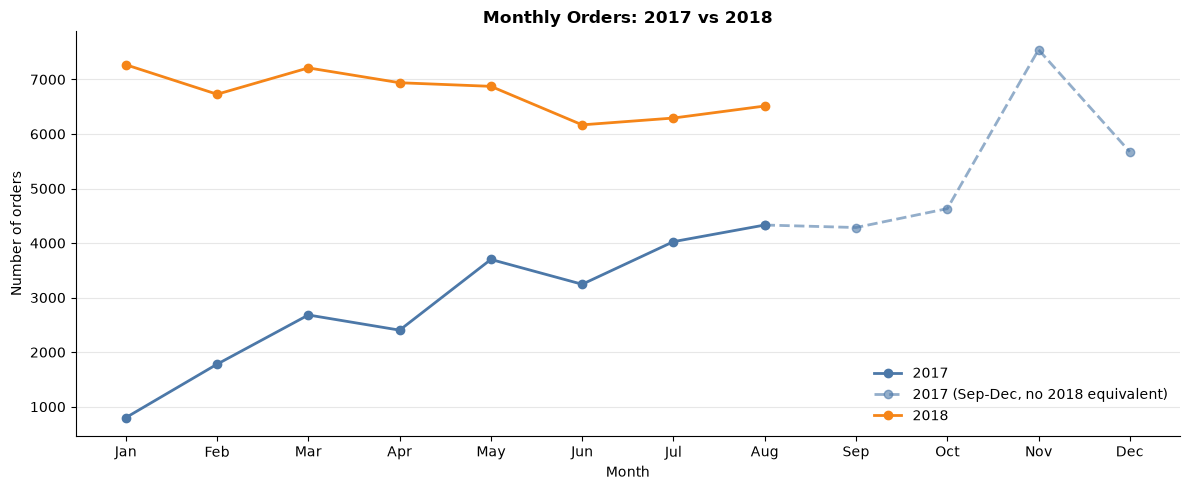

In [18]:
#comparable chart (year 2017 vs 2018)
# Pivot: rows = month number, columns = year
yoy = (monthly_order[monthly_order["order_year"].isin([2017, 2018])]
       .pivot(index="order_month", columns="order_year", values="orders_count"))

# 2018 is only valid through August
yoy_2018 = yoy[2018].where(yoy.index <= 8)

fig, ax = plt.subplots(figsize=(12, 5))

# 2017: solid for Jan-Aug (comparable), dashed for Sep-Dec (context only)
ax.plot(yoy.index[:8], yoy[2017][:8], marker="o", color="#4C78A8", linewidth=2, label="2017")
ax.plot(yoy.index[7:], yoy[2017][7:], marker="o", color="#4C78A8", linewidth=2,
        linestyle="--", alpha=0.6, label="2017 (Sep-Dec, no 2018 equivalent)")

ax.plot(yoy.index[:8], yoy_2018[:8], marker="o", color="#F58518", linewidth=2, label="2018")

ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_labels)
ax.set_title("Monthly Orders: 2017 vs 2018", fontweight="bold")
ax.set_xlabel("Month")
ax.set_ylabel("Number of orders")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

### Yearly and Monthly Comparison: Conclusion

**Question:** Has the store's activity increased over the period?

**Answer:** Yes over the whole period, but **not anymore in 2018**: all the growth happened in 2017, and 2018 was flat with a slight decline.

**Main insight: 2018 has stopped growing**
- Orders stayed between 6,167 and 7,269 per month. Per day, they fell from a peak of 240 (Feb) to about 210 (Aug), roughly −12%.
- Month-to-month changes were small, with as many ups as downs (4 and 4).

**Evidence**
- **Year over year (Jan to Aug, same months):** 2018 was higher than 2017 in all 8 months. The average rose from 2,871 to 6,749 orders per month (+135%). This is expected, because 2017 was the ramp-up year.
- **The gap is shrinking:** the YoY increase fell from +809% (Jan) to +50% (Aug), because 2017 kept growing while 2018 stayed flat.
- **2017:** orders grew from 800 (Jan) to 4,631 (Oct), then jumped 63% in Nov (7,544, driven by Black Friday). Increases outnumbered decreases (7 up, 4 down).
- **Top 5 months:** Nov 2017, Jan, Mar, Apr and May 2018 (1 from 2017, 4 from 2018), all within the later part of the window.

**Decision:** Order activity increased clearly over the dataset period, with a step-up around Nov 2017. After that, volume stabilized at about 6,200 to 7,300 orders per month, with a slight downward drift in 2018 rather than continued growth. Whether this is a temporary plateau or a real slowdown would need data after Aug 2018.

**Limitations**
- 2018 data is available only through August, so full-year totals and averages are not comparable between years.
- Only one full year exists, so seasonality can't be confirmed.
- Order count shows volume only, not revenue or customer satisfaction.

In [19]:
con.close()